Butterworth Filter Coefficients:
Numerator: [1.29607191e-05 5.18428766e-05 7.77643148e-05 5.18428766e-05
 1.29607191e-05]
Denominator: [ 1.         -3.67388572  5.07378356 -3.12116011  0.72146964]


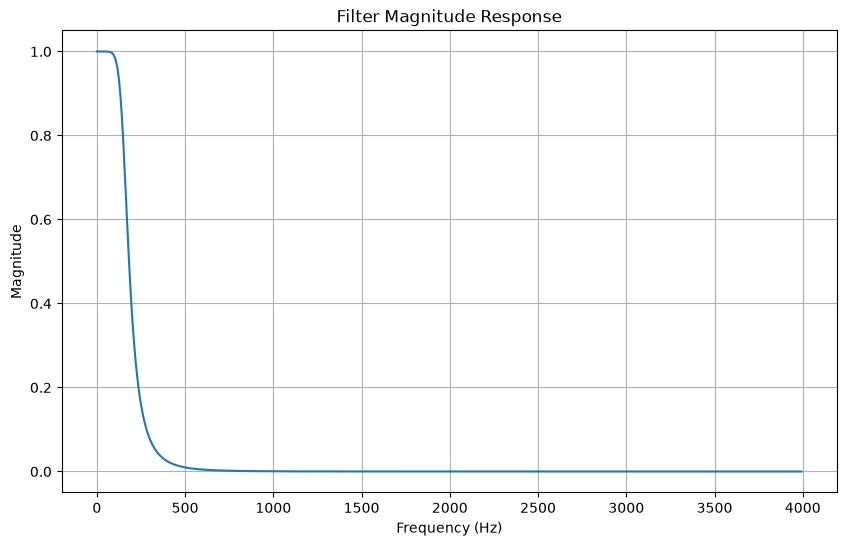

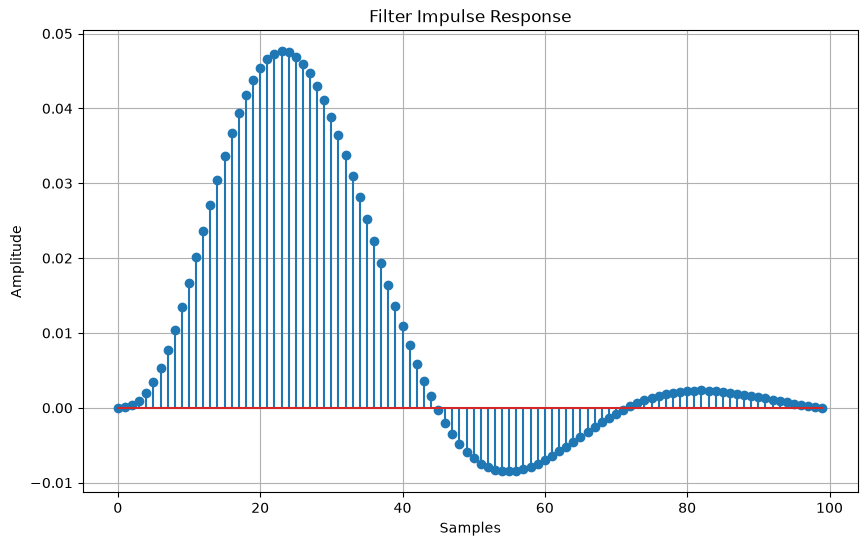

Chebyshev Filter Coefficients:
Numerator: [5.04743397e-06 2.01897359e-05 3.02846038e-05 2.01897359e-05
 5.04743397e-06]
Denominator: [ 1.         -3.83541526  5.53394882 -3.55962935  0.86118134]


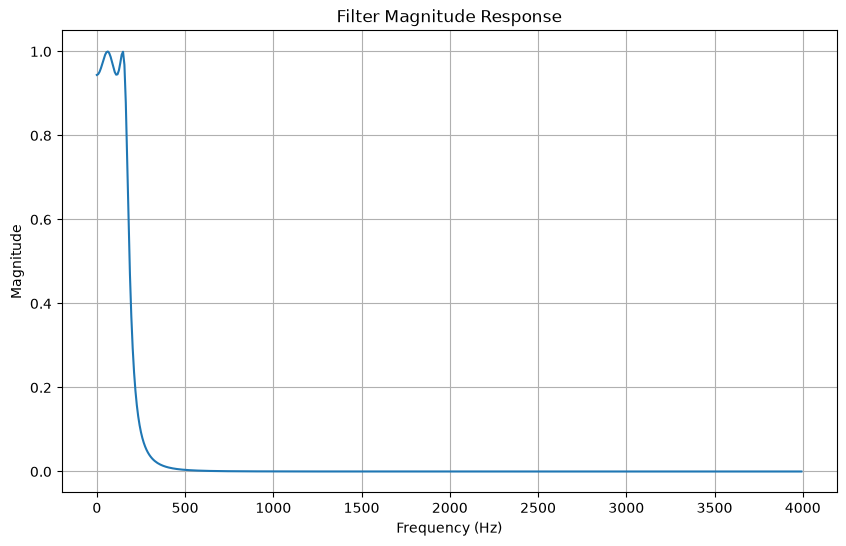

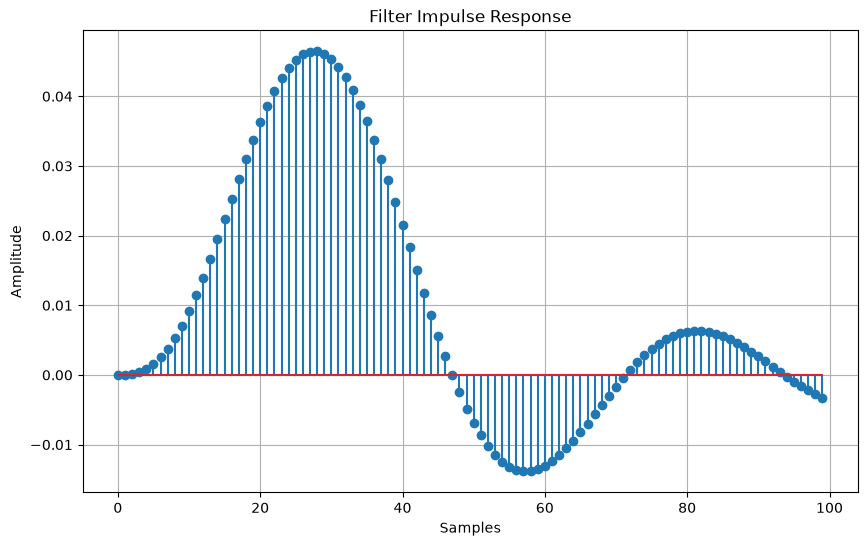

Filter coefficients saved at: filter_coefficients.txt


In [7]:
import numpy as np
import matplotlib.pyplot as plt 
from scipy.signal import butter, bilinear, freqz, cheby1


# Design Butterworth filter
def design_butterworth_filter(filter_order, cutoff_frequency, sampling_frequency):
    analog_b, analog_a = butter(
        filter_order,
        cutoff_frequency,
        analog=True,
        btype='low'
    )

    digital_b, digital_a = bilinear(
        analog_b,
        analog_a,
        sampling_frequency
    )

    return digital_b, digital_a


# Design Chebyshev filter
def design_chebyshev_filter(filter_order, cutoff_frequency, sampling_frequency, ripple):
    analog_b, analog_a = cheby1(
        filter_order,
        ripple,
        cutoff_frequency,
        analog=True,
        btype='low'
    )

    digital_b, digital_a = bilinear(
        analog_b,
        analog_a,
        sampling_frequency
    )

    return digital_b, digital_a


# Plot filter magnitude response and impulse response
def plot_filter_response(digital_b, digital_a, sampling_frequency):

    # Calculate frequency response
    frequency, magnitude_response = freqz(
        digital_b,
        digital_a,
        fs=sampling_frequency
    )

    # Plot magnitude response
    plt.figure(figsize=(10, 6))
    plt.plot(frequency, np.abs(magnitude_response))
    plt.title('Filter Magnitude Response')
    plt.xlabel('Frequency (Hz)')
    plt.ylabel('Magnitude')
    plt.grid(True)
    plt.show()

    # Calculate impulse response
    impulse = np.zeros(100)
    impulse[0] = 1

    from scipy.signal import lfilter

    impulse_response = lfilter(
        digital_b,
        digital_a,
        impulse
    )

    # Plot impulse response
    plt.figure(figsize=(10, 6))
    plt.stem(range(len(impulse_response)), impulse_response)
    plt.title('Filter Impulse Response')
    plt.xlabel('Samples')
    plt.ylabel('Amplitude')
    plt.grid(True)
    plt.show()


# Specify filter parameters
filter_order = 4
cutoff_frequency = 1000
sampling_frequency = 8000
ripple = 0.5


# Design and plot Butterworth filter
digital_b, digital_a = design_butterworth_filter(
    filter_order,
    cutoff_frequency,
    sampling_frequency
)

print("Butterworth Filter Coefficients:")
print("Numerator:", digital_b)
print("Denominator:", digital_a)

plot_filter_response(
    digital_b,
    digital_a,
    sampling_frequency
)


# Design and plot Chebyshev filter
digital_b, digital_a = design_chebyshev_filter(
    filter_order,
    cutoff_frequency,
    sampling_frequency,
    ripple
)

print("Chebyshev Filter Coefficients:")
print("Numerator:", digital_b)
print("Denominator:", digital_a)

plot_filter_response(
    digital_b,
    digital_a,
    sampling_frequency
)


# Save Chebyshev filter coefficients to a file
filter_path = 'filter_coefficients.txt'

np.savetxt(
    filter_path,
    np.vstack((digital_b, digital_a)),
    delimiter=','
)

print(f"Filter coefficients saved at: {filter_path}")
